In [221]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [222]:
data_train = pd.read_csv('data/train.csv')
data_test = pd.read_csv('data/test.csv')

target_name = 'Survived'
target = data_train[target_name]
trdata = data_train

tstdata = data_test.drop(columns='PassengerId')

In [223]:
trdata.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [224]:
trdata.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [225]:
trdata.isnull().sum().sort_values(ascending=False)

Cabin          687
Age            177
Embarked         2
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
SibSp            0
Parch            0
Ticket           0
Fare             0
dtype: int64

In [226]:
trdata.duplicated().sum()

np.int64(0)

In [227]:
x, y = target.value_counts(normalize=True)
print(x, y)

0.6161616161616161 0.3838383838383838


In [228]:
trdata.nunique()

PassengerId    891
Survived         2
Pclass           3
Name           891
Sex              2
Age             88
SibSp            7
Parch            7
Ticket         681
Fare           248
Cabin          147
Embarked         3
dtype: int64

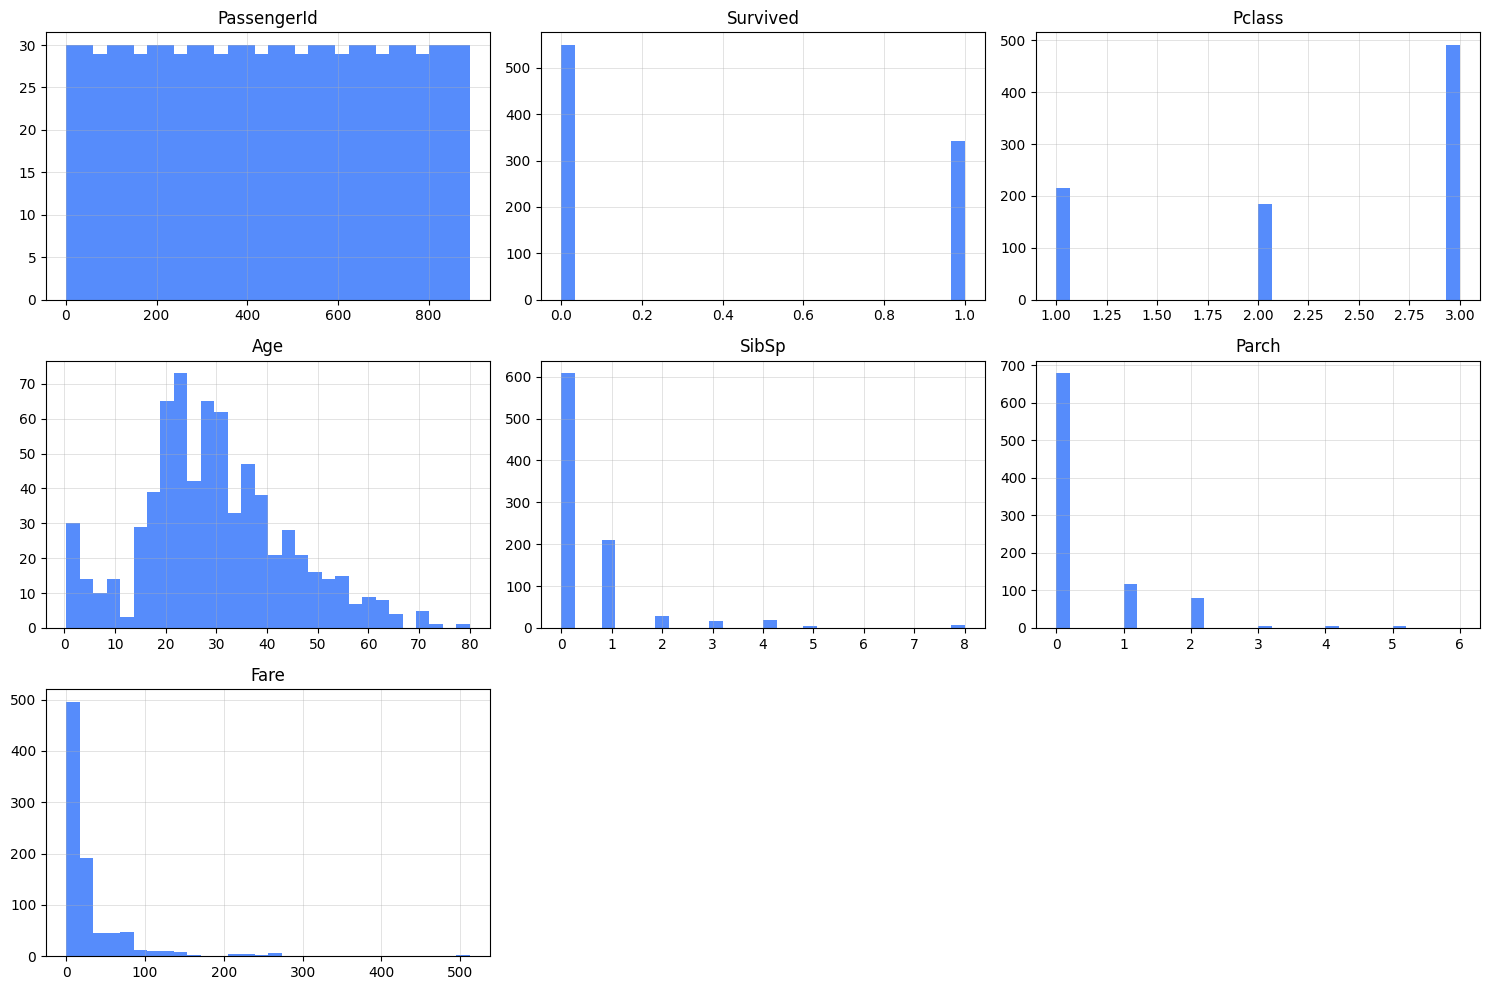

In [229]:
trdata.hist(figsize=(15, 10), bins=30)
plt.tight_layout()
plt.show()

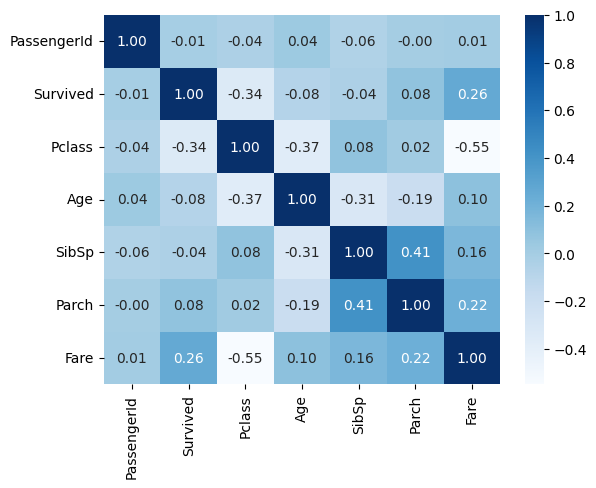

In [230]:
sns.heatmap(
    trdata.select_dtypes(include="number").corr(),
    cmap='Blues',
    annot=True,
    fmt=".2f"
)
plt.show()

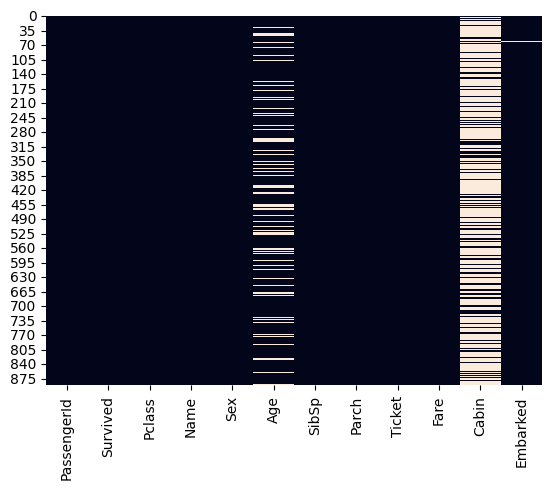

In [231]:
sns.heatmap(trdata.isna(), cbar=False)
plt.show()

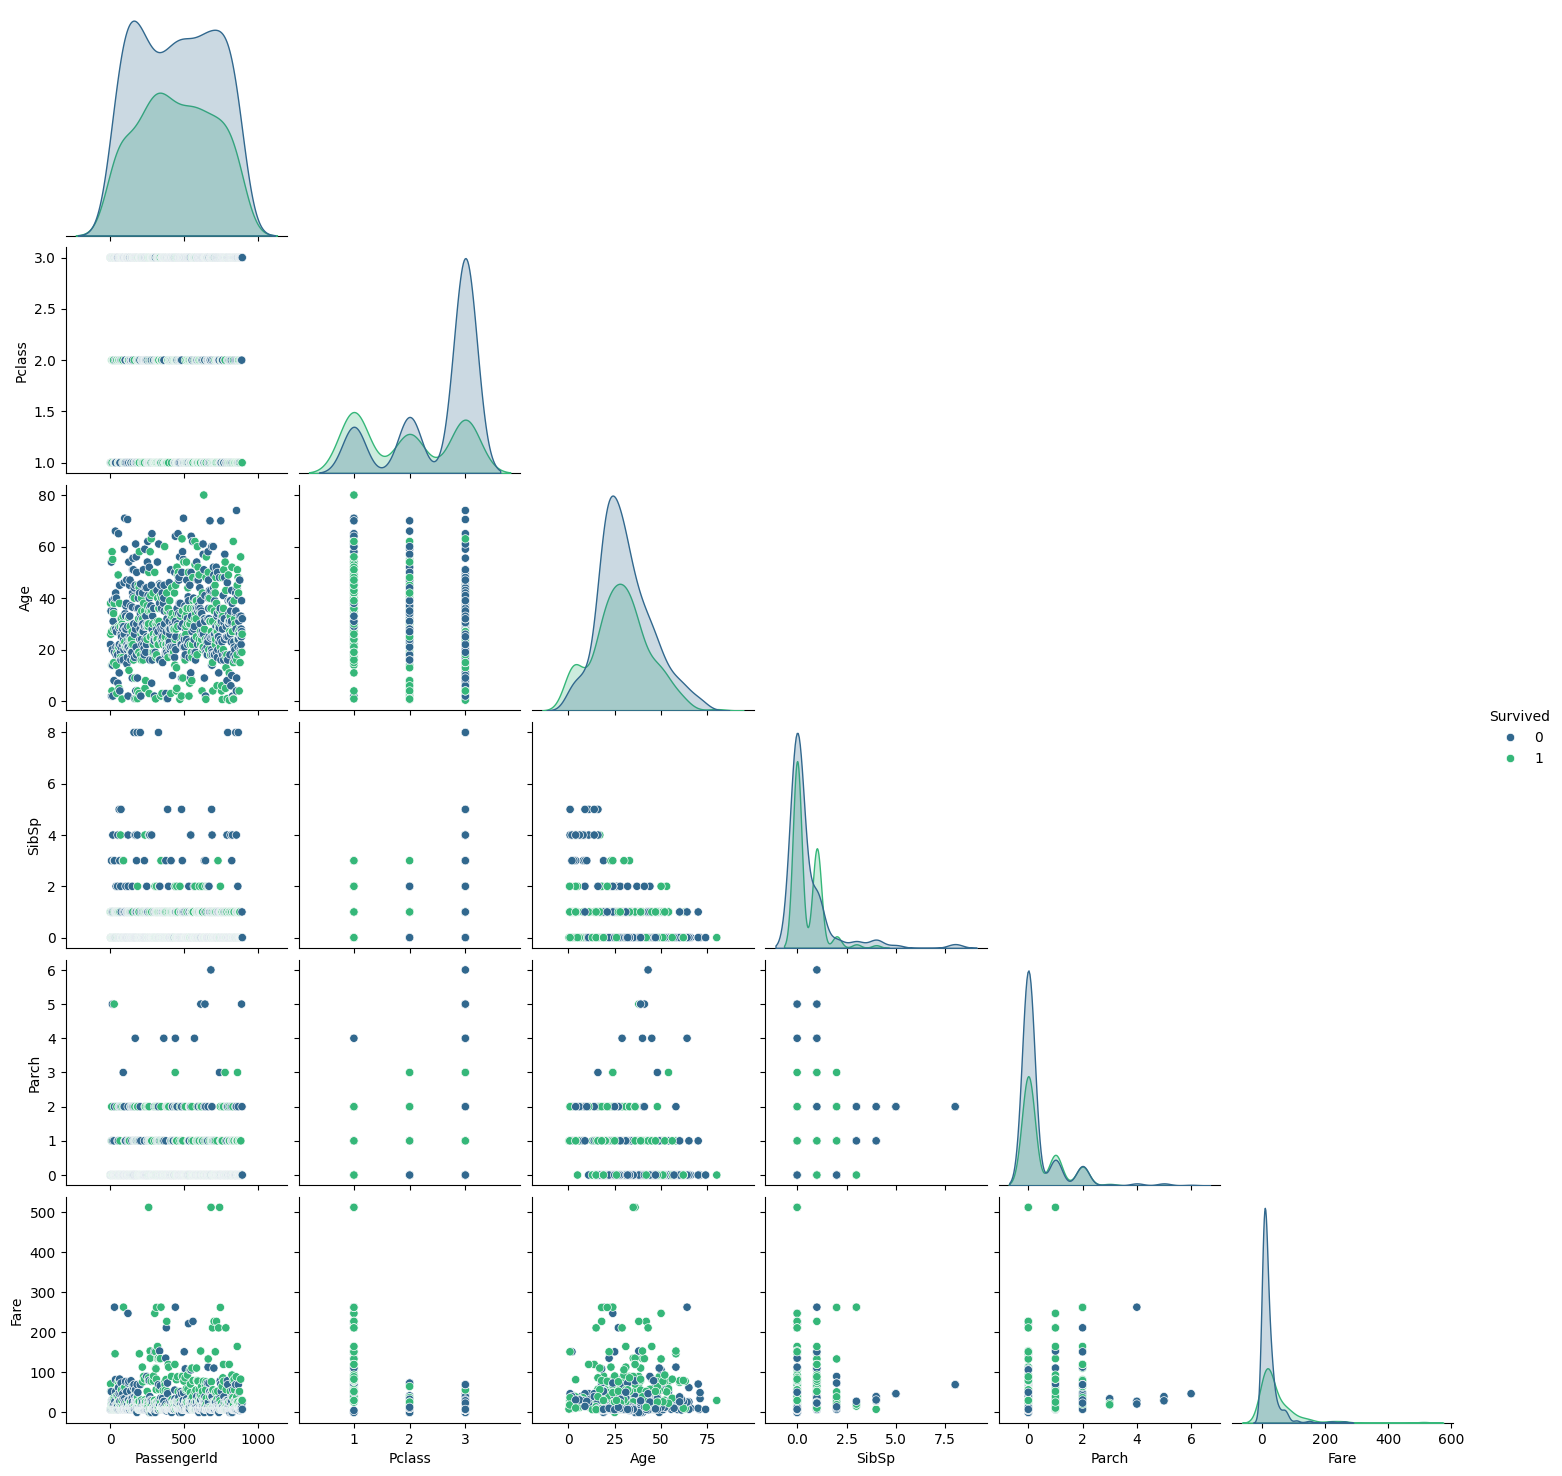

In [232]:
sns.pairplot(trdata, diag_kind="kde", hue='Survived', corner=True, palette="viridis")
plt.show()

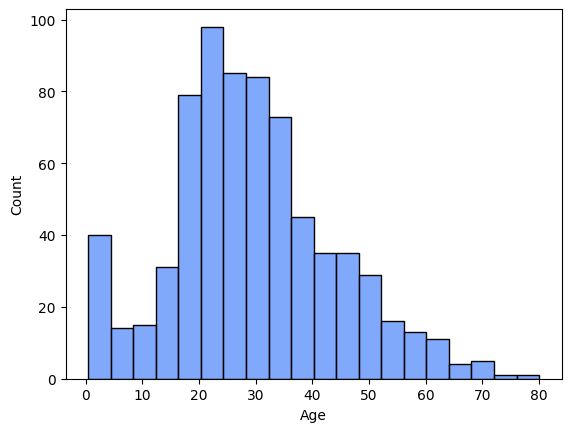

In [233]:
sns.histplot(data=trdata, x="Age")
plt.show()

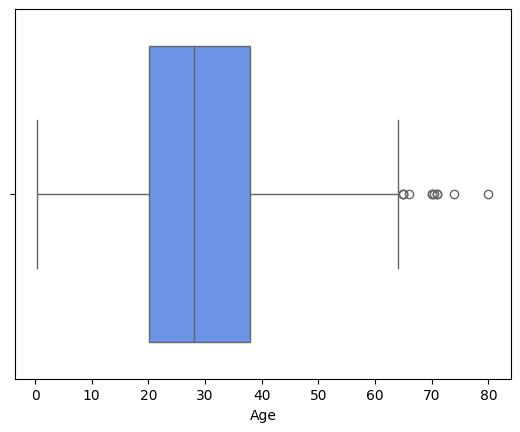

In [234]:
sns.boxplot(data=trdata, x="Age")
plt.show()

In [256]:
trdata = data_train.drop(columns=['Survived', 'PassengerId', 'Cabin'])

In [240]:
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(strategy='median')
trdata["Age"] = imputer.fit_transform(trdata[["Age"]])

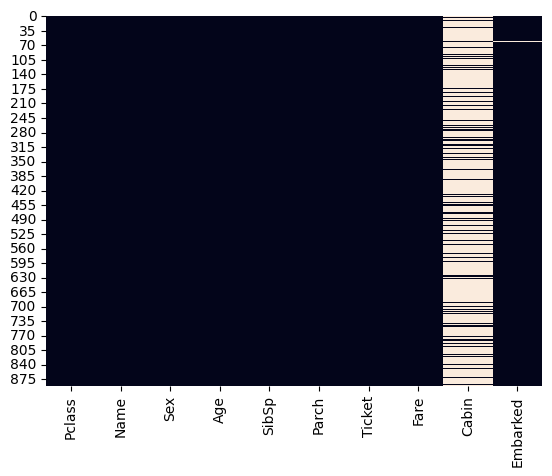

In [241]:
sns.heatmap(trdata.isna(), cbar=False)
plt.show()

In [253]:
imputer2 = SimpleImputer(strategy='most_frequent')
trdata['Embarked'] = imputer2.fit_transform(trdata[['Embarked']]).ravel()

In [255]:
# *
print(type(trdata["Age"]))

print(type(trdata[["Age"]]))

print(type(trdata["Age"].to_list()))


<class 'pandas.core.series.Series'>
<class 'pandas.core.frame.DataFrame'>
<class 'list'>


In [270]:
from sklearn.preprocessing import OneHotEncoder

encoder = OneHotEncoder(sparse_output=False)
sex_encoded = encoder.fit_transform(trdata[['Sex']])
encoder.categories_
trdata[['sex_female', 'sex_male']] = sex_encoded

In [277]:
encoder2 = OneHotEncoder(sparse_output=False)


imputer3 = SimpleImputer(strategy='most_frequent')

trdata["Embarked"] = imputer3.fit_transform(trdata[['Embarked']]).ravel()

embarked_encoded = encoder2.fit_transform(trdata[['Embarked']])
encoder2.categories_
trdata[['embarked_C', 'embarked_Q' , 'embarked_S']] = embarked_encoded

In [279]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()


,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked,sex_female,sex_male,embarked_C,embarked_Q,embarked_S
0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,S,0.0,1.0,0.0,0.0,1.0
1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C,1.0,0.0,1.0,0.0,0.0
2,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,S,1.0,0.0,0.0,0.0,1.0
3,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,S,1.0,0.0,0.0,0.0,1.0
4,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,S,0.0,1.0,0.0,0.0,1.0
